# 02. Моделювання, вибір порогу та пояснення моделі

Цей ноутбук пояснює, що робить `python -m churn.train` і **чому** саме так.
Сам код живе в `src/churn/`, а ноутбук лише викликає його та показує результати.
Так код можна тестувати й використовувати в API, а ноутбук лишається читабельним.

> Перед запуском виконайте `make train` (≈30 секунд). Він створює модель у `models/`
> і графіки в `reports/figures/`.

In [1]:
import json

import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.model_selection import train_test_split

from churn import config
from churn.data import load_dataset
from churn.predict import ChurnModel

report = json.loads((config.REPORTS_DIR / "metrics.json").read_text())
model = ChurnModel.load()
X, y = load_dataset()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=config.TEST_SIZE, stratify=y, random_state=config.RANDOM_STATE
)
print(f"Обрана модель: {report['selected_model']}, поріг: {report['threshold']:.2f}")

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Обрана модель: xgboost, поріг: 0.61


## 1. Схема валідації

```
7043 клієнти ──stratified split──► train 80% (5634)  ──► 5-fold CV: порівняння моделей
                                 │                     └─► out-of-fold прогнози: вибір порогу
                                 └► test 20% (1409)    ──► одна фінальна оцінка
```

**Чому так:**
* **Test відкладаємо одразу** і дивимось на нього один раз, наприкінці. Якщо обирати модель
  чи поріг по тесту, оцінка стане оптимістично зміщеною (ми «підігнали» рішення під тест).
* **Крос-валідація на train** дає не одне число, а середнє ± розкид по 5 фолдах.
  Так видно, чи різниця між моделями реальна, чи це шум.
* **Увесь препроцесинг всередині `Pipeline`.** Скейлер і one-hot навчаються лише на
  тренувальних фолдах, тож немає витоку даних (data leakage).

## 2. Порівняння моделей

| Модель | Навіщо в списку |
|---|---|
| `baseline` | Завжди прогнозує середню частку. Нижня межа: якщо модель не краща, вона марна. |
| `logreg` | Логістична регресія. Проста, швидка, інтерпретована. Сильний бейзлайн для табличних даних. |
| `random_forest` | Бегінг дерев: стійкий до шуму, ловить нелінійності. |
| `xgboost`, `lightgbm` | Градієнтний бустинг, стандарт індустрії для табличних даних. |

**Метрики:**
* **ROC-AUC** — ймовірність, що випадковий «відтічний» клієнт отримає вищий скор, ніж випадковий лояльний.
  Не залежить від порогу.
* **PR-AUC (average precision)** — площа під кривою precision-recall. Чутливіша до якості на рідшому
  класі, тому саме за нею обираємо модель. Для випадкової моделі PR-AUC = частці відтоку (0.265).

In [2]:
cv = pd.DataFrame(report["cv"]).T
cv[["roc_auc_mean", "roc_auc_std", "pr_auc_mean", "pr_auc_std", "fit_seconds"]].round(4)

,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,fit_seconds
baseline,0.5000,0.0000,0.2654,0.0001,0.36
logreg,0.8473,0.0115,0.6596,0.0160,0.52
random_forest,0.8484,0.0098,0.6622,0.0237,7.79
xgboost,0.8473,0.0104,0.6635,0.0224,1.29
lightgbm,0.8422,0.0093,0.6540,0.0218,1.93


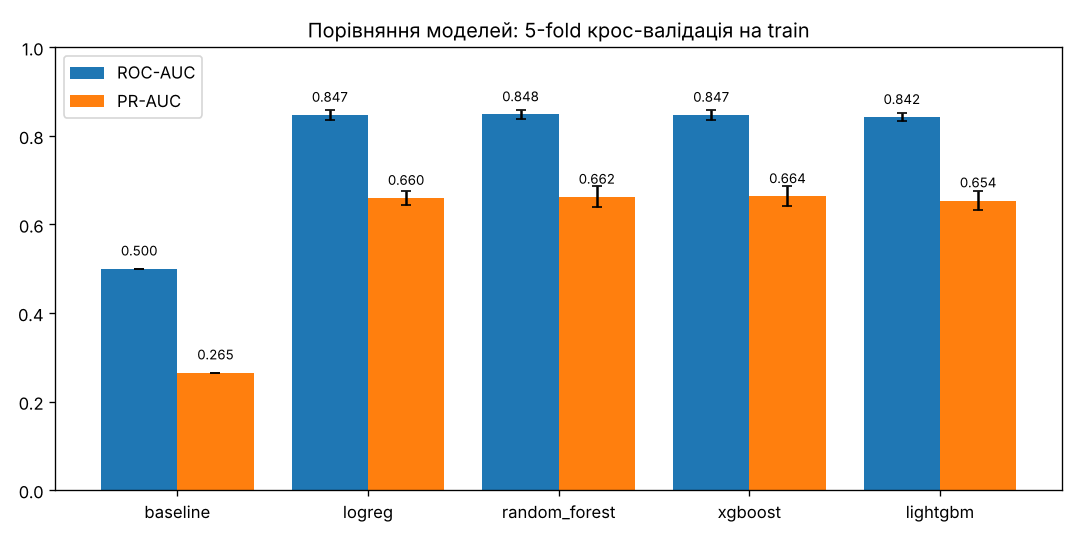

In [3]:
display(Image(config.FIGURES_DIR / "model_comparison.png"))

**Головний висновок:** логістична регресія, Random Forest і XGBoost відрізняються на тисячні,
а розкид між фолдами (±0.01–0.02) більший за цю різницю. Чесно сказати, що один алгоритм
«виграв», ми не можемо.

Це типова ситуація для невеликих табличних датасетів: **стеля якості визначається даними й ознаками,
а не алгоритмом**. Тому в реальному проєкті наступний крок — не тюнінг гіперпараметрів, а нові дані
(історія звернень у підтримку, використання трафіку, зміни тарифу).

За найвищим середнім PR-AUC обрано XGBoost. Логістична регресія була б рівноцінним вибором,
особливо якщо важлива простота.

## 3. Фінальна оцінка на тесті

In [4]:
rows = {"поріг 0.5": report["test_at_0.5"], f"поріг {report['threshold']:.2f}": report["test"]}
pd.DataFrame(rows).T[["roc_auc", "pr_auc", "precision", "recall", "f1", "brier"]].round(3)

,roc_auc,pr_auc,precision,recall,f1,brier
поріг 0.5,0.843,0.665,0.514,0.794,0.624,0.163
поріг 0.61,0.843,0.665,0.571,0.698,0.628,0.163


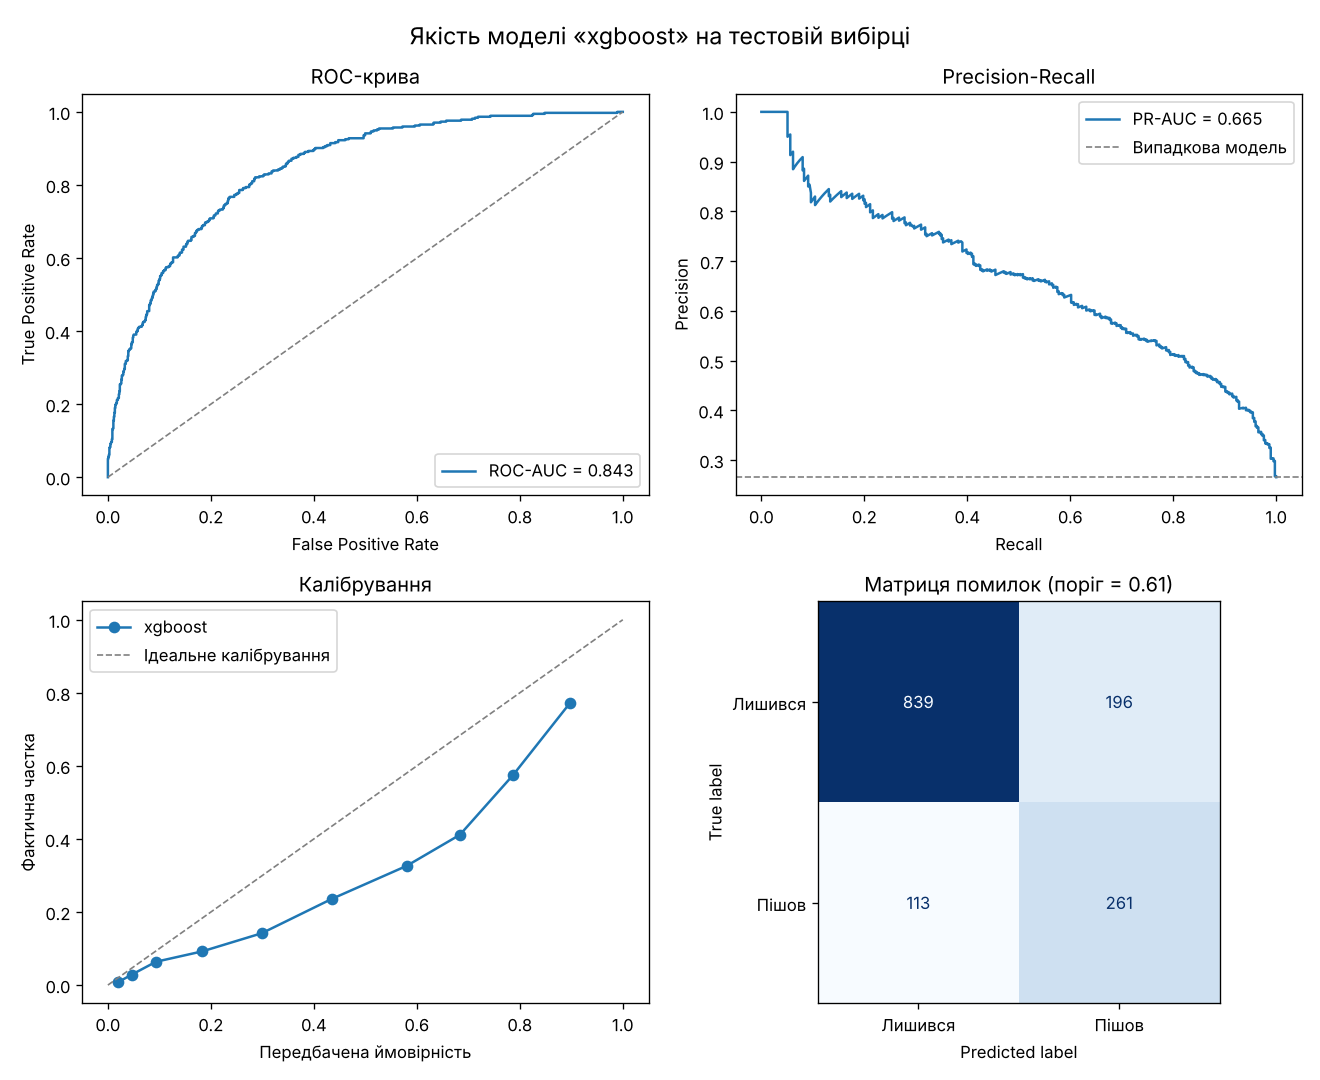

In [5]:
display(Image(config.FIGURES_DIR / "model_report.png"))

**Як читати графіки:**
* **ROC-AUC ≈ 0.84 на тесті** збігається з крос-валідацією, тобто модель не перенавчилась.
* **Матриця помилок.** Модель знаходить ~70% тих, хто справді піде (recall), і ~57% її «тривог»
  правдиві (precision).
* **Калібрування.** Крива лежить *нижче* діагоналі, тобто модель завищує ймовірності.
  Це очікуваний побічний ефект `scale_pos_weight`: ми штучно «підсилили» рідкий клас.
  Для ранжування й вибору порогу це не заважає, але якщо бізнесу потрібна чесна ймовірність
  («70% шанс, що піде»), варто додати `CalibratedClassifierCV` (див. «Що покращити» в README).

## 4. Поріг: від ймовірності до рішення

Поріг 0.5 — довільне число. Правильний поріг залежить від **вартості помилок**. Припущення
(їх легко змінити в `config.py`):

| Параметр | Значення | Сенс |
|---|---|---|
| `CUSTOMER_VALUE` | 500 $ | дохід, який ми зберігаємо, утримавши клієнта |
| `OFFER_COST` | 50 $ | вартість пропозиції (знижки) |
| `OFFER_SUCCESS_RATE` | 30% | частка тих, кого пропозиція справді втримає |

* **TP** (піде, ми запропонували): `0.3 × 500 − 50 = +100 $`
* **FP** (не пішов би, а ми дали знижку): `−50 $`
* **FN, TN:** 0 $ (нічого не робили)

Поріг обираємо так, щоб максимізувати прибуток **на out-of-fold прогнозах train**, а не на тесті.

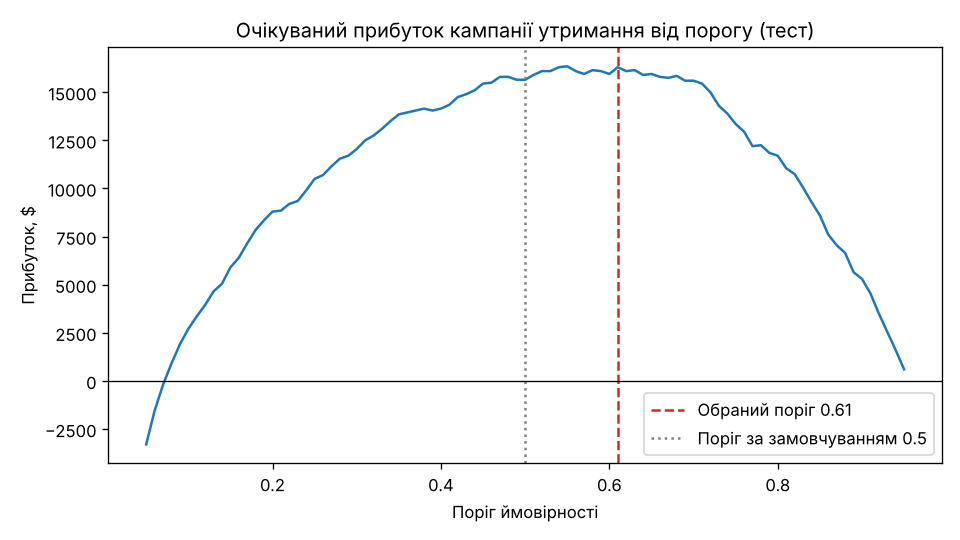

,"Прибуток на тесті, $"
"Модель, обраний поріг",16300.0
"Модель, поріг 0.5",15650.0
Пропозиція всім,-14350.0
Нікому,0.0


In [6]:
display(Image(config.FIGURES_DIR / "profit_curve.png"))
p = report["profit_test"]
pd.Series({
    "Модель, обраний поріг": p["model_at_threshold"],
    "Модель, поріг 0.5": p["model_at_0.5"],
    "Пропозиція всім": p["contact_everyone"],
    "Нікому": p["contact_nobody"],
}, name="Прибуток на тесті, $").to_frame()

Розіслати знижку всім означає *збиток*, бо ми платимо 50 $ і тим, хто б не пішов. Модель перетворює
ту саму кампанію на прибуткову. Для бізнесу це головний аргумент, набагато зрозуміліший за «AUC 0.84».

## 5. Пояснення моделі (SHAP)

Метрики кажуть, *наскільки добре* працює модель. SHAP каже, *як* вона приймає рішення.

Для кожного клієнта SHAP розкладає прогноз (у логітах) на суму внесків ознак:
`logit(p) = базове значення + внесок_1 + внесок_2 + …`. Внесок > 0 підвищує ризик відтоку,
< 0 знижує його.

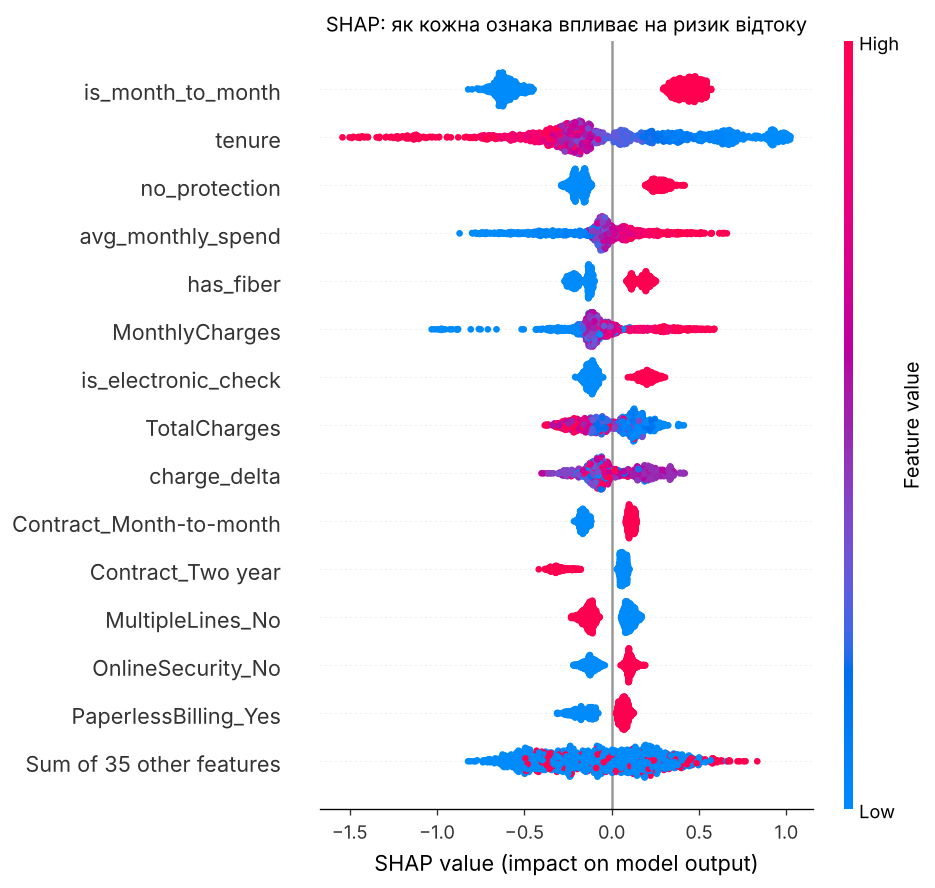

In [7]:
display(Image(config.FIGURES_DIR / "shap_beeswarm.png"))

**Як читати beeswarm:** кожна точка — клієнт; позиція по X — внесок ознаки; колір — значення
ознаки (червоний = високе).

* **`is_month_to_month`** — найважливіша ознака. Помісячний договір (червоні точки) стабільно штовхає ризик вгору.
* **`tenure`**: короткий стаж (сині точки) різко збільшує ризик, довгий (червоні) зменшує.
* **`no_protection`**, **`has_fiber`**, **`is_electronic_check`** — усі ознаки, які ми сконструювали з EDA,
  потрапили в топ. Це підтверджує, що feature engineering був корисним.
* Модель «вивчила» те саме, що ми побачили на графіках EDA. Це хороша перевірка здорового глузду.

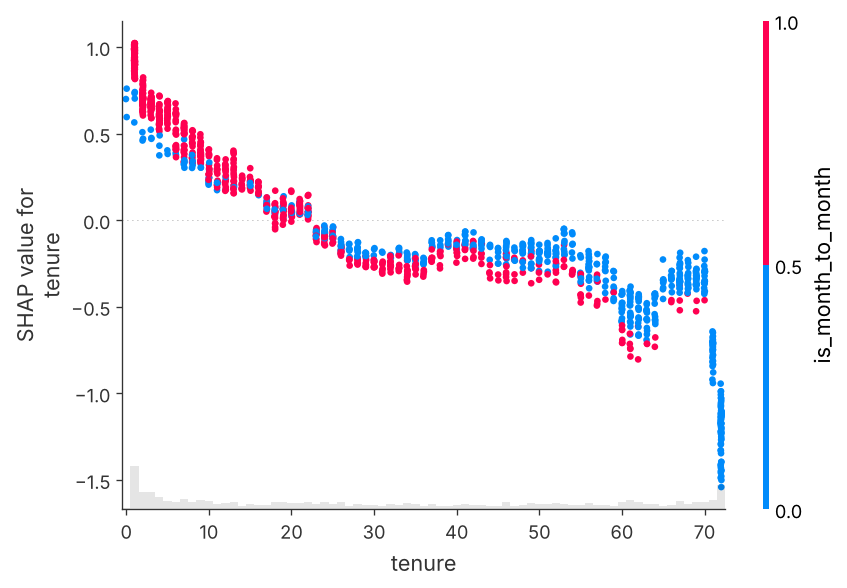

In [8]:
display(Image(config.FIGURES_DIR / "shap_dependence_tenure.png"))

**Dependence plot для `tenure`:** внесок падає зі стажем і стає від'ємним приблизно після 1.5–2 років.
Колір показує `is_month_to_month`: у перші місяці помісячний договір (червоний) робить короткий стаж
ще ризиковішим, тобто модель вловила взаємодію, яку ми бачили на heatmap в EDA.

Різкий обвал на `tenure = 72` — артефакт даних: стаж у датасеті обрізано на 72 місяцях, тому там зібрані
всі найлояльніші клієнти (і майже всі на дворічних договорах). Такі «стіни» на графіках варто помічати.

### Пояснення для одного клієнта

Саме це повертає API в полі `top_factors`: менеджер з утримання бачить не лише «ризик 91%»,
а й **чому**, і може запропонувати релевантну дію (наприклад, річний договір або TechSupport у подарунок).

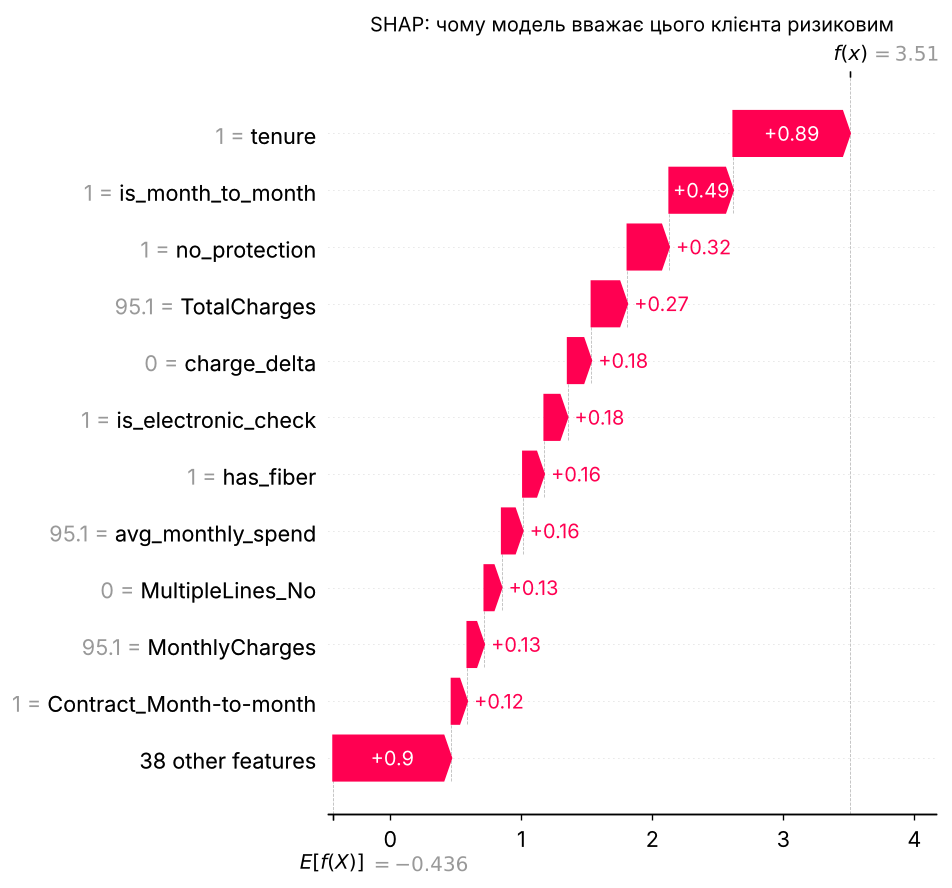

In [9]:
display(Image(config.FIGURES_DIR / "shap_waterfall_example.png"))

In [10]:
sample = X_test.iloc[[0, 1, 2]]
proba = model.predict_proba(sample)
for (idx, row), p, factors in zip(sample.iterrows(), proba, model.explainer.top_factors(sample, k=3)):
    print(f"Клієнт {idx}: ризик {p:.0%}, tenure={row.tenure}, {row.Contract}, {row.PaymentMethod}")
    for f in factors:
        print(f"    {f['feature']:<22} = {f['value']:>7.2f}  {f['impact']:+.2f}  ({f['direction']})")

Клієнт 437: ризик 6%, tenure=72, Two year, Credit card (automatic)
    tenure                 =   72.00  -1.17  (зменшує ризик)
    is_month_to_month      =    0.00  -0.65  (зменшує ризик)
    avg_monthly_spend      =  117.61  +0.35  (збільшує ризик)
Клієнт 2280: ризик 89%, tenure=8, Month-to-month, Credit card (automatic)
    tenure                 =    8.00  +0.51  (збільшує ризик)
    is_month_to_month      =    1.00  +0.43  (збільшує ризик)
    MonthlyCharges         =  100.15  +0.33  (збільшує ризик)
Клієнт 2235: ризик 18%, tenure=41, One year, Credit card (automatic)
    is_month_to_month      =    0.00  -0.60  (зменшує ризик)
    charge_delta           =    0.03  +0.17  (збільшує ризик)
    no_protection          =    0.00  -0.16  (зменшує ризик)


## Підсумок

1. Базова лінія → 4 моделі → чесне порівняння крос-валідацією: моделі рівні, вирішують дані.
2. Тест використано один раз: ROC-AUC 0.84, PR-AUC 0.66.
3. Поріг обрано за грошима, а не за звичкою.
4. SHAP показує, що модель спирається на ті самі фактори, що й EDA, і пояснює кожен прогноз.

Далі: модель доступна через REST API (`api/main.py`) і Docker. Див. README.